# 🏆 Compound Edge Gold Strategy (1.1x Risk/Reward)

### Overview
This notebook implements a high-performance algorithmic trading strategy for **Gold (XAUUSD)** on the 15-minute timeframe. 

**The Core Philosophy:**
Instead of trying to catch every trade, we identify high-probability **Market Tops (Peaks)** and use Machine Learning to determine the precise **Entry Buffer (Alpha)** required to enter a Short position safely.

### Key Logic:
1.  **Peak Detection:** We identify local maxima (peaks) in price history.
2.  **Machine Learning:** A Gradient Boosting Regressor analyzes volatility, momentum, and volume to predict an **Alpha Ratio ($k$)**.
3.  **Dynamic Entry:** The entry price is calculated as: $Entry = Close_{P1} - (k \times ATR)$.
4.  **Compound Edge:** We use a **1:1.1 Risk/Reward Ratio**. By winning slightly more than we lose ($110 vs $100), we create a mathematical edge that compounds over time.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
import warnings
import os

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Setup Plotting Style
plt.style.use('ggplot')
print("Libraries Loaded Successfully.")

Libraries Loaded Successfully.


## 1. Load Data
Ensure your dataset (`XAU_15m_data.csv`) is in the same directory as this notebook. The expected format is `Date;Open;High;Low;Close;Volume`.

In [16]:
FILE_PATH = 'XAU_15m_data.csv'

if not os.path.exists(FILE_PATH):
    print(f"❌ Error: File '{FILE_PATH}' not found. Please upload the CSV file.")
else:
    start_date = "2010-01-01"
    df = pd.read_csv(FILE_PATH, delimiter=';')
    # Clean columns
    df.columns = [c.strip() for c in df.columns]
    # Parse Dates
    df['Date'] = pd.to_datetime(df['Date'], format='%Y.%m.%d %H:%M')
    if start_date:
        df = df[df['Date'] >= pd.to_datetime(start_date)]
    else:
        pass
    # Sort chronologically
    df = df.sort_values('Date').reset_index(drop=True)
    
    print(f"✅ Data Loaded. Shape: {df.shape}")
    display(df.head())

✅ Data Loaded. Shape: (365328, 6)


,Date,Open,High,Low,Close,Volume
0,2010-01-04 01:00:00,1094.61,1095.00,1093.08,1093.40,744
1,2010-01-04 01:15:00,1093.75,1096.45,1093.35,1095.65,1020
2,2010-01-04 01:30:00,1095.36,1096.15,1094.28,1095.68,721
3,2010-01-04 01:45:00,1095.72,1096.90,1094.25,1094.49,879
4,2010-01-04 02:00:00,1094.95,1095.95,1094.00,1095.37,901


## 2. Feature Engineering
We create a rich set of features to help the AI understand market context.

*   **ATR:** Measures absolute volatility.
*   **Vol_Ratio:** Is volatility expanding or contracting?
*   **RSI & RSI Slope:** Momentum direction and speed.
*   **Relative Volume:** Distinguishes real peaks from fake ones.
*   **Candle Morphology:** Shadow sizes and body sizes.

In [17]:
print("Engineering Features...")

# --- 1. Volatility (ATR) ---
df['HL'] = df['High'] - df['Low']
df['HC'] = abs(df['High'] - df['Close'].shift(1))
df['LC'] = abs(df['Low'] - df['Close'].shift(1))
df['TR'] = df[['HL', 'HC', 'LC']].max(axis=1)
df['ATR'] = df['TR'].rolling(window=14).mean()

# --- 2. Volatility Ratio ---
# (Current ATR / Average ATR)
df['Vol_MA'] = df['ATR'].rolling(window=50).mean()
df['Vol_Ratio'] = df['ATR'] / (df['Vol_MA'] + 0.0001)

# --- 3. Momentum (RSI & Slope) ---
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df['RSI'] = 100 - (100 / (1 + rs))

# RSI Slope: Change in RSI over 3 candles
df['RSI_Slope'] = df['RSI'] - df['RSI'].shift(3)

# --- 4. Relative Volume ---
df['Volume_MA'] = df['Volume'].rolling(window=20).mean()
df['Rel_Vol'] = df['Volume'] / (df['Volume_MA'] + 1)

# --- 5. Candle Morphology ---
df['Body_Size'] = abs(df['Close'] - df['Open'])
df['Upper_Shadow'] = df['High'] - df[['Open', 'Close']].max(axis=1)
df['Hour'] = df['Date'].dt.hour

# Drop NaNs
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Feature Engineering Complete.")

Engineering Features...
Feature Engineering Complete.


## 3. Target Generation (The Oracle)
We identify historical peaks and ask: *"What Alpha (Entry Buffer) was needed here?"*

*   If the trade was a **Winner**, we teach the AI to output a small Alpha (`0.25`).
*   If the trade was a **Loser**, we teach the AI to output a huge Alpha (`5.0`), effectively avoiding the trade.

In [18]:
print("Generating Targets...")

# Find Local Peaks (Highs surrounded by 5 lower Highs)
peaks_indices = argrelextrema(df['High'].values, np.greater_equal, order=5)[0]
dataset = []

for idx in peaks_indices:
    if idx < 50 or idx + 100 >= len(df): continue

    # P0: The Peak
    p0_high = df.loc[idx, 'High']
    
    # P1: Entry Candle (2 candles after peak)
    p1_idx = idx + 2
    p1 = df.loc[p1_idx]

    if pd.isna(p1['ATR']): continue

    # Capture Features
    features = {
        'ATR': p1['ATR'],
        'Vol_Ratio': p1['Vol_Ratio'],
        'RSI': p1['RSI'],
        'RSI_Slope': p1['RSI_Slope'],
        'Hour': p1['Hour'],
        'Dist_P0_P1_ATR': (p0_high - p1['Close']) / p1['ATR'],
        'P1_Body_ATR': p1['Body_Size'] / p1['ATR'],
        'P1_Upper_Shadow_ATR': p1['Upper_Shadow'] / p1['ATR'],
        'P1_Rel_Vol': p1['Rel_Vol'],
        
        # Metadata
        'P1_Close': p1['Close'],
        'P0_High': p0_high,
        'P1_Index': p1_idx,
        'Date': p1['Date']
    }

    # --- LABELING LOGIC ---
    # We label based on a 1:1 scenario to train the model conservatively.
    risk_dist = p0_high - p1['Close']
    target_price = p1['Close'] - risk_dist
    
    future = df.loc[p1_idx+1 : p1_idx+50]
    
    sl_hit = future[future['High'] > p0_high]
    tp_hit = future[future['Low'] < target_price]
    
    first_sl_idx = sl_hit.index[0] if not sl_hit.empty else 9999999
    first_tp_idx = tp_hit.index[0] if not tp_hit.empty else 9999999
    
    if first_tp_idx < first_sl_idx:
        features['Target_Alpha_Ratio'] = 0.25 # Good Trade
    else:
        features['Target_Alpha_Ratio'] = 5.0  # Bad Trade
        
    dataset.append(features)

ml_data = pd.DataFrame(dataset)
print(f"Labeled Data Created. Samples: {len(ml_data)}")

Generating Targets...
Labeled Data Created. Samples: 23252


## 4. Train Machine Learning Model
We use **Gradient Boosting** (sklearn) to learn the complex non-linear relationships between our features (RSI, Volume, etc.) and the outcome.

Training Model...
Model Trained Successfully!


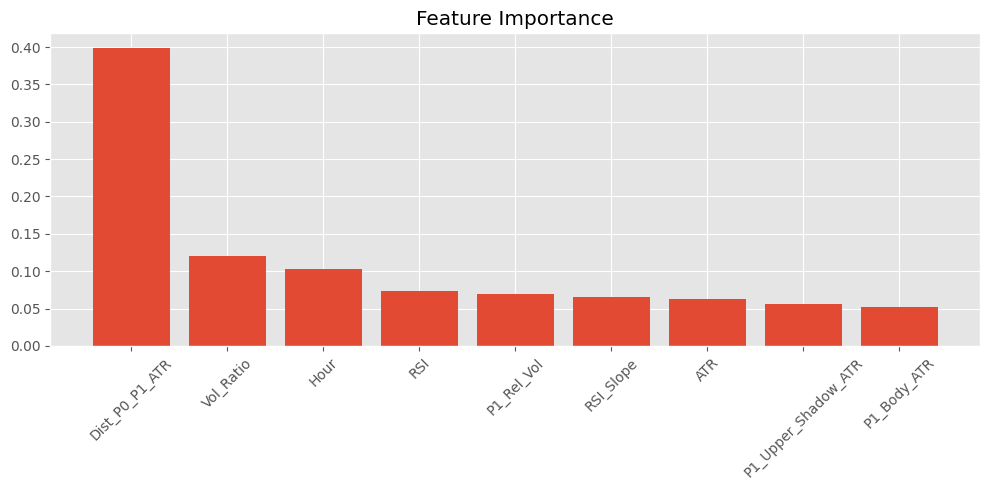

In [19]:
print("Training Model...")

# 80/20 Time Series Split
split = int(len(ml_data) * 0.8)
train_df = ml_data.iloc[:split]
test_df = ml_data.iloc[split:].copy()

feature_cols = ['ATR', 'Vol_Ratio', 'RSI', 'RSI_Slope', 'Hour', 
                'Dist_P0_P1_ATR', 'P1_Body_ATR', 'P1_Upper_Shadow_ATR', 'P1_Rel_Vol']
y_col = 'Target_Alpha_Ratio'

model = GradientBoostingRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.04,
    subsample=0.8,
    random_state=42
)

model.fit(train_df[feature_cols], train_df[y_col])
print("Model Trained Successfully!")

# Feature Importance Plot
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 5))
plt.title("Feature Importance")
plt.bar(range(len(feature_cols)), importances[indices], align="center")
plt.xticks(range(len(feature_cols)), [feature_cols[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()

## 5. Backtesting Engine (The Simulation)
We now simulate trading on the unseen data (the last 20%).

**Strategy Rules:**
1.  **AI Filter:** If `Predicted Alpha > 1.5`, reject trade.
2.  **RSI Filter:** If `RSI < 35`, reject trade (oversold).
3.  **Entry Formula:** $Entry = Close - \max(0.2, PredictedRatio) \times ATR$
4.  **Compound Edge:** **Take Profit** is set to **1.1x** the Risk distance.

In [20]:
print("Running Simulation (Compound Edge 1.1x)...")

test_df['Predicted_Ratio'] = model.predict(test_df[feature_cols])

capital = 10000
risk_per_trade = 100 
balance_history = [capital]

wins = 0
losses = 0
filtered_count = 0

for idx, row in test_df.iterrows():
    
    pred_ratio = row['Predicted_Ratio']
    
    # --- FILTER 1: AI Confidence ---
    if pred_ratio > 1.5:
        filtered_count += 1
        balance_history.append(capital)
        continue

    # --- FILTER 2: RSI Safety ---
    if row['RSI'] < 35:
        filtered_count += 1
        balance_history.append(capital)
        continue
        
    # --- ENTRY CALCULATION ---
    atr = row['ATR']
    
    # Alpha Formula
    alpha_usd = pred_ratio * atr
    if alpha_usd < 0.2 * atr: 
        alpha_usd = 0.2 * atr
        
    entry_price = row['P1_Close'] - alpha_usd
    stop_loss = row['P0_High']
    
    if entry_price >= stop_loss: continue
        
    # --- COMPOUND EDGE (1.1x Reward) ---
    risk = stop_loss - entry_price
    target = entry_price - (risk * 1.1) 
    
    # --- CHECK OUTCOME ---
    p1_idx = int(row['P1_Index'])
    future = df.loc[p1_idx+1 : p1_idx+100]
    
    outcome = 0 
    filled = False
    
    for i, candle in future.iterrows():
        # 1. Fill Logic
        if not filled:
            if candle['Low'] <= entry_price:
                filled = True
                if candle['High'] >= stop_loss:
                    outcome = -1
                    break
        
        # 2. Trade Management
        if filled:
            if candle['High'] >= stop_loss:
                outcome = -1
                break
            if candle['Low'] <= target:
                outcome = 1
                break
    
    # Update Balance
    if outcome == 1:
        capital += (risk_per_trade * 1.1) # Win $110
        wins += 1
    elif outcome == -1:
        capital -= risk_per_trade # Lose $100
        losses += 1
        
    balance_history.append(capital)

print("Simulation Complete.")

Running Simulation (Compound Edge 1.1x)...
Simulation Complete.



 FINAL STRATEGY REPORT
Total Opportunities:      4651
Filtered (AI/RSI):        3346
Trades Taken:             1206
Wins:                     628
Losses:                   578
-----------------------------------
Win Rate:                 52.07%
Net Profit:               $11280.00
Final Balance:            $21280.00


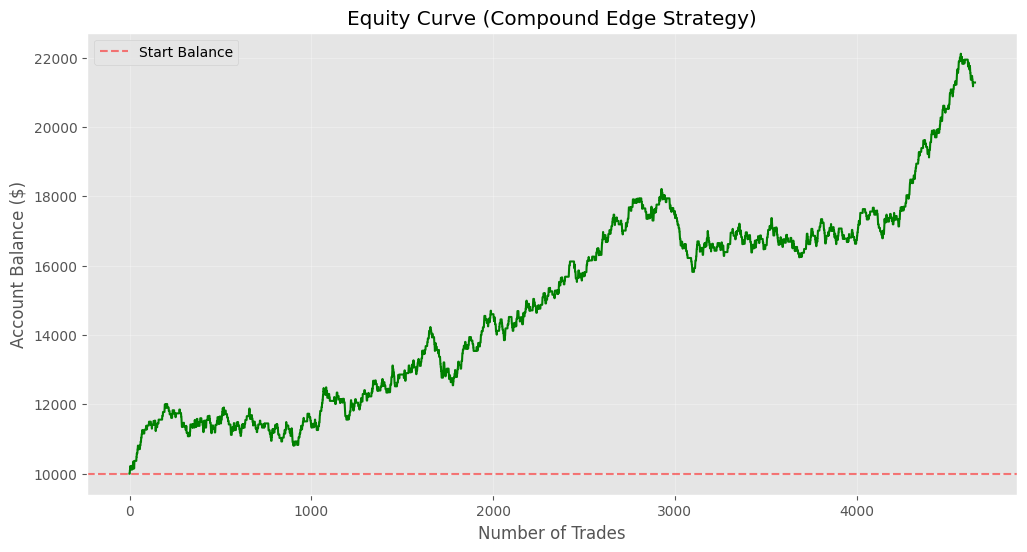

In [21]:
# --- REPORTING ---
total_trades = wins + losses
win_rate = (wins / total_trades * 100) if total_trades > 0 else 0
net_profit = capital - 10000

print("\n" + "="*35)
print(" FINAL STRATEGY REPORT")
print("="*35)
print(f"Total Opportunities:      {len(test_df)}")
print(f"Filtered (AI/RSI):        {filtered_count}")
print(f"Trades Taken:             {total_trades}")
print(f"Wins:                     {wins}")
print(f"Losses:                   {losses}")
print("-" * 35)
print(f"Win Rate:                 {win_rate:.2f}%")
print(f"Net Profit:               ${net_profit:.2f}")
print(f"Final Balance:            ${capital:.2f}")
print("="*35)

# Plot Equity Curve
plt.figure(figsize=(12, 6))
plt.plot(balance_history, color='green', linewidth=1.5)
plt.title('Equity Curve (Compound Edge Strategy)')
plt.xlabel('Number of Trades')
plt.ylabel('Account Balance ($)')
plt.axhline(y=10000, color='r', linestyle='--', alpha=0.5, label='Start Balance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()